In [37]:
# Import required libaries
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split,GridSearchCV, ParameterGrid
import xgboost as xgb
import prince
import warnings
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy import linalg
import seaborn as sns
from stepmix.stepmix import StepMix


# Own code

import Code.preprocess

In [38]:
# loading in the (anonymized) data
df = pd.read_csv("P1_2425_C1_Answers_Anon.csv")

# Shape of data
print("Shape of data:\n",df.shape)
print("Number of students:\n",df.shape[0])

#Ignore warnings
warnings.filterwarnings('ignore')

# First 5 rows of whole data set (including exam questions + survey questions)
df.head()

Shape of data:
 (184, 42)
Number of students:
 184


,Student number,1,2,5,6,7,8,9,10,11,...,37,38,39,40,49,50,51,52,53,54
0,0,A,A,B,A,a,b,A,A,c,...,A,B,B,B,A,A,B,EFC,E,C
1,1,A,A,B,b,B,A,A,A,B,...,b,B,B,B,A,A,B,DABCEF,E,D
2,2,A,A,B,A,a,b,A,A,a,...,A,a,B,a,A,A,B,E,E,D
3,3,A,A,B,A,B,A,A,A,c,...,A,a,B,a,A,A,C,ABE,E,B
4,4,A,A,B,A,B,A,A,A,c,...,A,B,B,B,A,D,E,ADE,E,B


In [39]:
# Keep only relevant columns (learning strategies)
df = df[['49','52','53','54']]

# Pre processing steps (Documentation available in the code)
df = Code.preprocess.remove_no_consent(df,df["49"],remove_nan=True)

df = Code.preprocess.translate(df)


Shape: (128, 4)
Number of people who gave consent: 128
Difference with total: 56, Percentage: 69.57%


<Axes: >

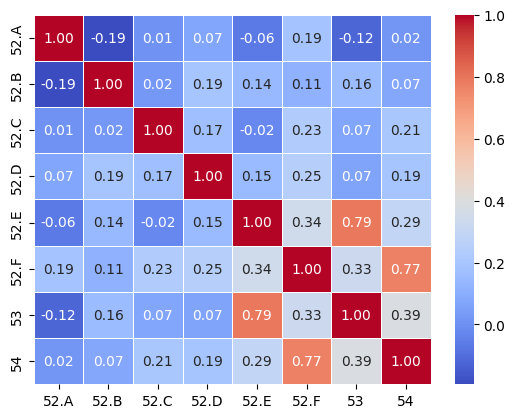

In [41]:
# Correlation
corr = df.corr()
sns.heatmap(corr,annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

In [ ]:

survey_answers_learning_strategies.shape

In [ ]:
# Visualize data

sns.clustermap(survey_answers_learning_strategies)

In [ ]:
# Train Test split to prevent daka leakage (80% train, 20% test)
X = survey_answers_learning_strategies

X_train, X_test = train_test_split(
X,  test_size=0.2, random_state=42)

In [ ]:
# Data is categorical and discrete so MCA will be used before putting into a GMM
mca = prince.MCA(
    n_components=8,
    engine='sklearn',
    random_state=42,
    one_hot=False, # one hot encoding is done
    check_input=True,
    copy=True)
mca = mca.fit(X_train)
# X_ = mca.row_coordinates(X)
X_train = mca.row_coordinates(X_train)
X_test = mca.row_coordinates(X_test)

In [ ]:
mca.eigenvalues_summary

In [ ]:
X_test.head()

In [ ]:
# X_train = X_train.iloc[:,:4]
# X_test = X_test.iloc[:,:4]

In [ ]:
X_test.head()

In [ ]:
X_train.head()

In [ ]:
mca.plot(
    X,
    x_component=0,
    y_component=1,
    show_column_markers=True,
    show_row_markers=True,
    show_column_labels=False,
    show_row_labels=False,
)

In [ ]:
mca.column_contributions_.style.format("{:.0%}")

In [ ]:
gm = GaussianMixture(n_components=5,random_state=42).fit(X_train)

In [ ]:
gm.means_

In [ ]:
# Testing using the BIC (choose lowest)
components = range(1,7)

models = [] # List of fitted models
for n in components:
    gm = GaussianMixture(n_components=n,random_state=42,n_init=20).fit(X_train)
    print(f'components:{n}\n\tBIC:{gm.bic(X_test):.2f}\n\tAIC:{gm.aic(X_test):.2f}')
    models.append(gm)
"""
Both methods clearly agree on using 3 components
"""

In [ ]:
chosen_component = 3
chosen_model = models[chosen_component - 1]

colors = ['blue','green','red',"purple","grey"]
fig,ax = plt.subplots()
ax.scatter(X_train.iloc[:,0],X_train.iloc[:,1],label='train')
ax.scatter(X_test.iloc[:,0],X_test.iloc[:,1],label='test')

for n in range(chosen_component):
    mean = chosen_model.means_[n,:2]
    covariance = chosen_model.covariances_[n][:2,:2]
    
    v,w = linalg.eigh(covariance)
    
    angle = np.arctan2(w[0][1],w[0][0])
    angle = 180.0 * angle / np.pi
    v = 2.0 * np.sqrt(2.0) * np.sqrt(v)
    # covariance = 
    ellipse = Ellipse(mean,v[0],v[1],angle = 180.0 + angle,color=colors[n])
    ellipse.set_clip_box(fig.bbox)
    ellipse.set_alpha(0.5)
    ax.add_patch(ellipse)
    
    
fig.legend()
fig.show()

In [ ]:
survey_answers_learning_strategies

In [ ]:
X = survey_answers_learning_strategies_unnorm



In [ ]:
X

In [ ]:
# LCA
# model = StepMix(n_components=3, measurement="categorical",random_state=42)
# model.fit(survey_answers_learning_strategies_unnorm)


components = range(1,7)

models = [] # List of fitted models
for n in components:
    model = StepMix(n_components=n, measurement="categorical",random_state=42,n_init=20).fit(X)
    print(f'components:{n}\n\tBIC:{model.bic(X):.2f}\n\tAIC:{model.aic(X):.2f}')
    models.append(model)


"""
We see that the BIC also prefers for 3 compontents just like a GMM. 
"""

In [ ]:
# Already try to make a tree based algorithm implentation for later with fake data


In [ ]:
points = pd.read_csv("P1_2425_C1_Points_Anon.csv")
points.head()

In [ ]:
points.shape

In [ ]:
# Add total points of each student as an extra column
total = points.sum(axis=1).round(1)
# X['points'] = total
# X.head()
total

In [ ]:
X

In [ ]:
# assign points to kept rows
total = total.loc[X.index]


In [ ]:
# Load dataframe into DMatrix
data = X 
label = total
dtrain = xgb.DMatrix(data, label=label)

In [ ]:
# Parameters (regression)
param = {'max_depth': 2, 'eta': 1, 'objective': 'reg:squarederror'}
param['nthread'] = 4
param['eval_metric'] = 'rmse'
bst = xgb.train(param,dtrain)

In [ ]:
# plot importance

xgb.plot_importance(bst)